### Visualize the data for the insights

In [1]:
## load the dataset
import pandas as pd
import warnings
warnings.filterwarnings("ignore")
ratings = pd.read_csv(r"C:\AI_2026\Projects\BookRecommentationSystem\BookRecommentorSystemData\Ratings.csv")
books = pd.read_csv(r"C:\AI_2026\Projects\BookRecommentationSystem\BookRecommentorSystemData\Books.csv")

In [2]:
ratings.head()

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


## top 5 book rated by users

In [3]:
## top 5 book rated by users
top_rated_books_isbn = ratings.groupby('ISBN')['Book-Rating'].count().sort_values(ascending=False)
top_rated_books_isbn.head()

ISBN
0971880107    2502
0316666343    1295
0385504209     883
0060928336     732
0312195516     723
Name: Book-Rating, dtype: int64

In [4]:
indices = books[books["ISBN"].isin(top_rated_books_isbn.index)]
merged_data_5_users = pd.merge(indices,top_rated_books_isbn.reset_index(),on="ISBN")

In [5]:
rated_by_users = merged_data_5_users.sort_values(by="Book-Rating",ascending=False).head()

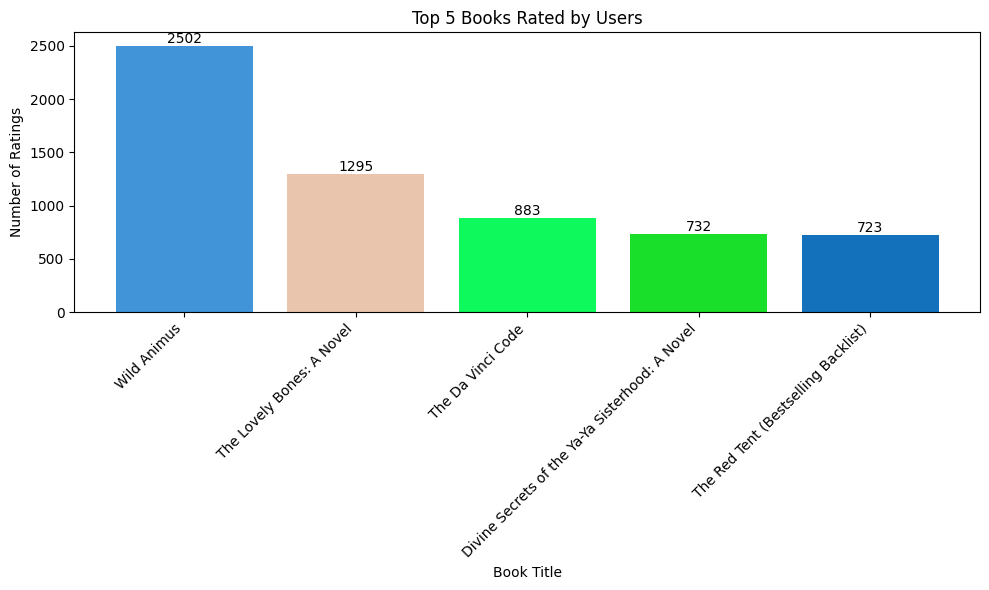

In [14]:
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline
plt.figure(figsize=(10,6))

bar =plt.bar(rated_by_users["Book-Title"], rated_by_users["Book-Rating"],color=np.random.rand(5,3))
plt.bar_label(bar)
plt.xlabel("Book Title")
plt.ylabel("Number of Ratings")
plt.title("Top 5 Books Rated by Users")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## top 5 rated users

In [7]:
top_5_users = ratings.groupby("User-ID")["Book-Rating"].count().sort_values(ascending=False).head()
top_5_users

User-ID
11676     13602
198711     7550
153662     6109
98391      5891
35859      5850
Name: Book-Rating, dtype: int64

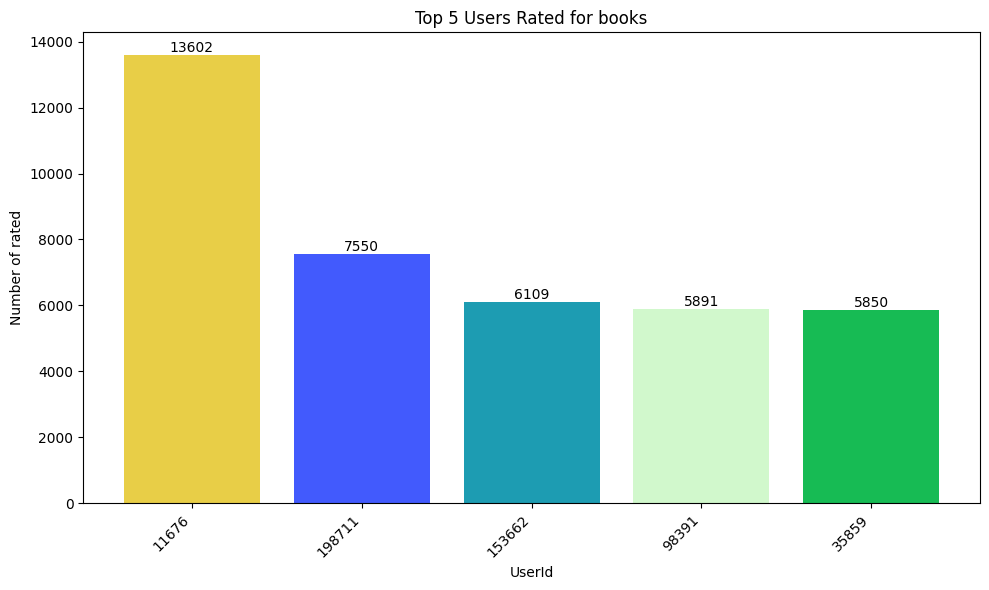

In [15]:
plt.figure(figsize=(10,6))
bar=plt.bar(top_5_users.index.astype("str"), top_5_users.values,color=np.random.rand(5,3))
plt.bar_label(bar)
plt.xlabel("UserId")
plt.ylabel("Number of rated")
plt.title("Top 5 Users Rated for books")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Proportion of ratings given by users


In [9]:
## Proportion of ratings given by users
rating_counts = ratings['Book-Rating'].value_counts().sort_values()
rating_counts

Book-Rating
1       1770
2       2759
3       5996
4       8904
6      36924
5      50974
9      67541
7      76457
10     78610
8     103736
0     716109
Name: count, dtype: int64

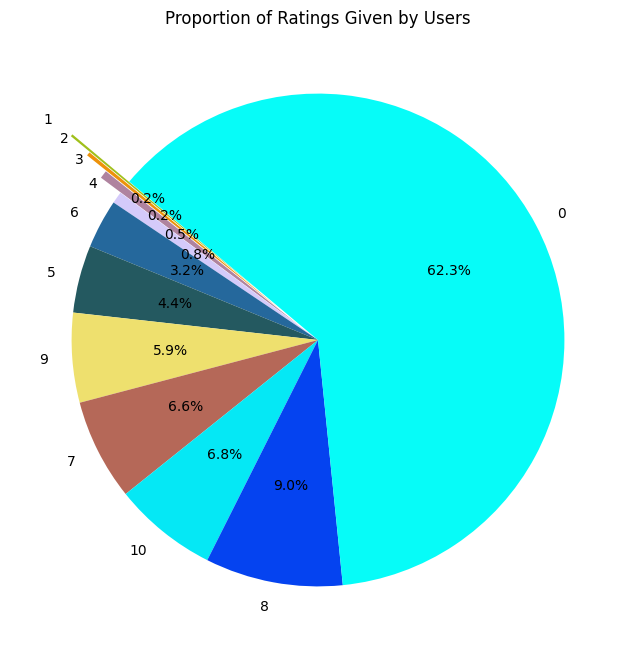

In [10]:
plt.figure(figsize=(8,8))
plt.pie(rating_counts.values, labels=rating_counts.index, autopct='%1.1f%%', startangle=140, colors=np.random.rand(11,3),explode=[0.3,0.2,0.1,0,0,0,0,0,0,0,0])
plt.title("Proportion of Ratings Given by Users")
plt.show()

## top 5 Author written books

In [11]:
authors_by_books = books.groupby("Book-Author")["Book-Title"].count().sort_values(ascending=False).head()
authors_by_books

Book-Author
Agatha Christie        632
William Shakespeare    567
Stephen King           524
Ann M. Martin          423
Carolyn Keene          373
Name: Book-Title, dtype: int64

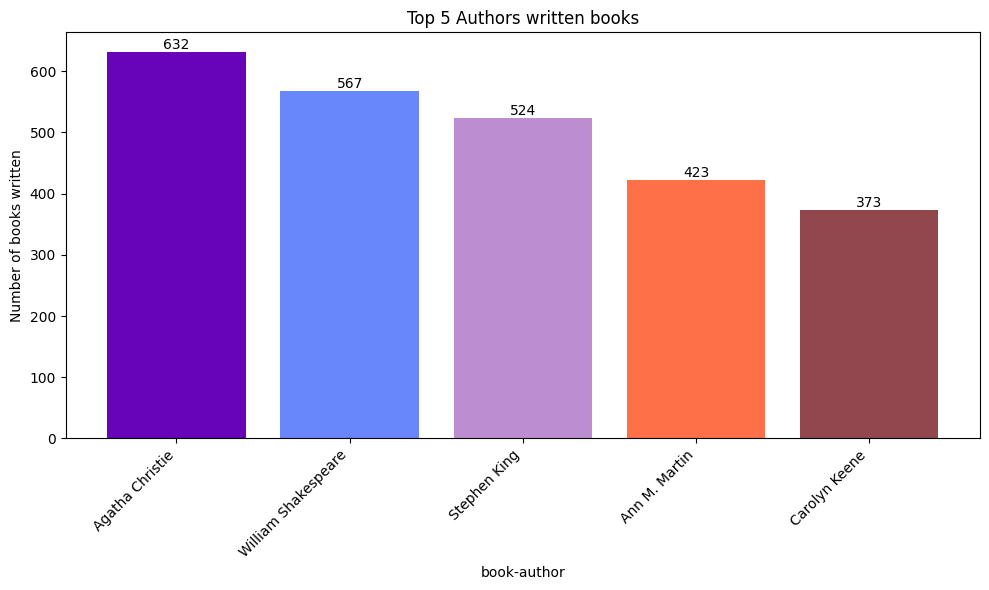

In [16]:
plt.figure(figsize=(10,6))
bar = plt.bar(authors_by_books.index.astype("str"), authors_by_books.values,color=np.random.rand(5,3))
plt.bar_label(bar)
plt.xlabel("book-author")
plt.ylabel("Number of books written")
plt.title("Top 5 Authors written books")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Top 5 Publishers irrespective of total book published

In [19]:
max_book_publishers = books.groupby("Publisher")["Book-Title"].count().sort_values(ascending=False).head()
max_book_publishers

Publisher
Harlequin           7535
Silhouette          4220
Pocket              3905
Ballantine Books    3783
Bantam Books        3646
Name: Book-Title, dtype: int64

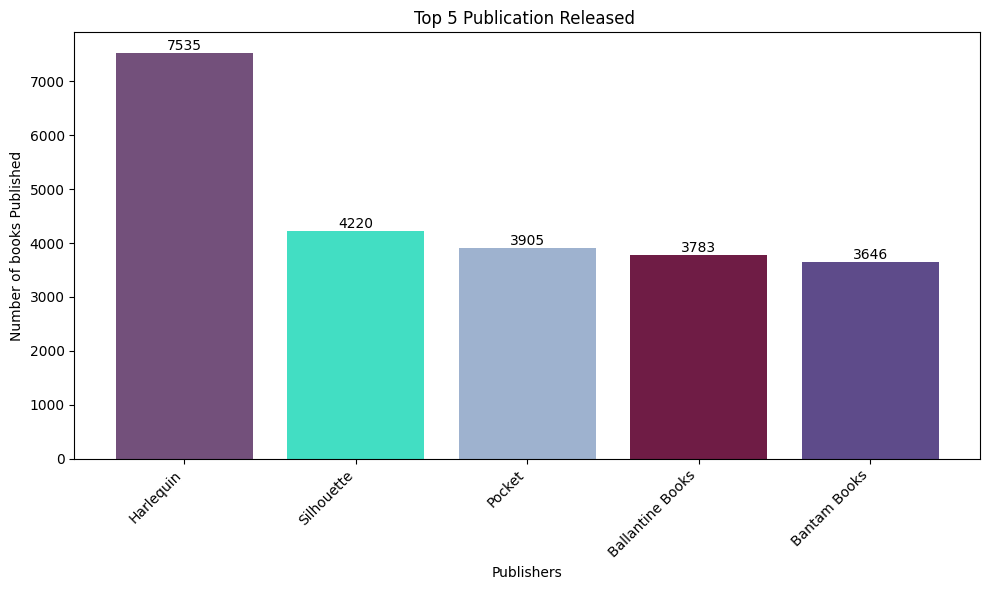

In [20]:
plt.figure(figsize=(10,6))
bar = plt.bar(max_book_publishers.index.astype("str"), max_book_publishers.values,color=np.random.rand(5,3))
plt.bar_label(bar)
plt.xlabel("Publishers")
plt.ylabel("Number of books Published")
plt.title("Top 5 Publication Released ")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## total books released over the year

In [ ]:
import seaborn as sns
count_books_per_year = books.groupby("Year-Of-Publication")["Book-Title"].count().sort_values(ascending=False)

In [29]:
count_books_per_year

Year-Of-Publication
2002         13903
2001         13715
1999         13414
2000         13373
1998         12116
             ...  
2012             1
2024             1
2020             1
2037             1
Gallimard        1
Name: Book-Title, Length: 202, dtype: int64

In [21]:
books.columns


Index(['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher',
       'Image-URL-S', 'Image-URL-M', 'Image-URL-L'],
      dtype='str')